# Разобранный эксперимент
Это синтетические назначения, не реальный A/B-тест магазина. Пользователь — единица; 7-дневное окно к as_of созрело. Нормальная аппроксимация допустима для этих больших бинарных групп.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "data").is_dir(), "Откройте блокнот из папки комплекта"
sys.path.insert(0, str(ROOT))
import pandas as pd
from analysis import basic, independent_basic, normalized, export_basic

from analysis import experiment
from scipy.stats import chisquare
import matplotlib.pyplot as plt

In [2]:
result=experiment(as_of="2026-01-10T00:00:00Z")
display(pd.DataFrame([result]).T)
assert result["nA"]==2000 and result["xA"]==200
assert result["nB"]==2000 and result["xB"]==240

,0
nA,2000
nB,2000
xA,200
xB,240
pA,0.1
pB,0.12
difference,0.02
ci_low,0.000617
ci_high,0.039383
p_two_sided,0.043245


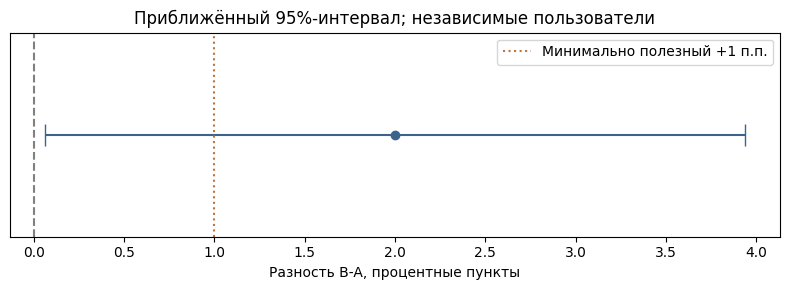

In [3]:
fig,ax=plt.subplots(figsize=(8,3))
d=result["difference"]*100
low=result["ci_low"]*100;high=result["ci_high"]*100
ax.errorbar(d,0,xerr=[[d-low],[high-d]],fmt="o",color="#3c638c",capsize=8)
ax.axvline(0,color="gray",linestyle="--");ax.axvline(1,color="#bb7540",linestyle=":",label="Минимально полезный +1 п.п.")
ax.set_yticks([]);ax.set_xlabel("Разность B-A, процентные пункты")
ax.set_title("Приближённый 95%-интервал; независимые пользователи")
ax.legend();fig.tight_layout();fig.savefig(ROOT / "outputs/experiment-ci.png",dpi=160)
plt.show()

In [4]:
stat,p=chisquare([600,400],f_exp=[500,500])
print("SRM statistic:",stat,"p:",p)
print("Bonferroni for 4:",.05/4)

SRM statistic: 40.0 p: 2.539628589470864e-10
Bonferroni for 4: 0.0125


In [5]:
try:
    experiment(ROOT / "experiments/assignments-defect.csv")
except ValueError as error:
    print("ASSIGNMENT REJECTED:",error)
else:
    raise AssertionError("Expected rejection")

ASSIGNMENT REJECTED: User assigned more than once or missing


## Решение по этому учебному набору
Номинальный двухсторонний p около 0.043. При четырёх гипотезах порог 0.0125 не пройден. Интервал допускает эффект меньше +1 п.п., поэтому минимальная практическая польза также не подтверждена этим интервалом. Отсутствие SRM не заменяет проверки назначения, экспозиции и зрелости. Это учебная интерпретация синтетических чисел, не утверждение о настоящем продукте.

## Ваша очередь
В новой копии файла измените число успехов, сохраните целостность единиц, пересчитайте и напишите experiments/decision.md по своему плану. Не подбирайте method/p-value до красивого результата.